In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 35.3 MB/s  0:00:02


# Task 03 — Student Performance Prediction (Regression)
**Goal:** predict the *Performance Index* (10–100) of a student. **Target:** `Performance Index`. **Features:** Hours Studied, Previous Scores, Extracurricular Activities, Sleep Hours (`Sample Question Papers Practiced` is dropped, see the reason below).

**Metrics:** MAE, MSE, RMSE and R².

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import re
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Load the data

In [3]:
import os
path = 'dataset/Student_Performance.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'Student_Performance.csv'
df = pd.read_csv(path)

# The first column of the file has no name (pandas calls it 'Unnamed: 0'); its values are 1-9 = study hours
df = df.rename(columns={'Unnamed: 0': 'Hours Studied'})

In [4]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [5]:
df.shape

(10000, 6)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [7]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,7144.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.572788,55.224800
std,2.589309,17.343152,1.695863,2.868633,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [8]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='object')

## 2. Data cleaning

In [9]:
df.duplicated().sum()

np.int64(132)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.isnull().sum().sort_values(ascending=False).head()

,0
Sample Question Papers Practiced,2778
Extracurricular Activities,1563
Previous Scores,0
Hours Studied,0
Sleep Hours,0


**Missing values:** the old code filled `Extracurricular Activities` with the most frequent value of the *whole* data before splitting (data leakage, and 15% of the students were given a guessed value). Now the missing ones become a separate category `Unknown`. Nothing is learned from the data, so there is no leakage.

In [12]:
# 'Extracurricular Activities' is categorical (Yes / No): 15% are missing.
# Instead of guessing "the most frequent value" we keep them as their own category 'Unknown'.
df['Extracurricular Activities'] = df['Extracurricular Activities'].fillna('Unknown')
print(df['Extracurricular Activities'].value_counts())

Extracurricular Activities
No         4193
Yes        4112
Unknown    1563
Name: count, dtype: int64


In [13]:
# Why do we drop 'Sample Question Papers Practiced'?
col = 'Sample Question Papers Practiced'
print(f"Missing: {df[col].isnull().mean():.0%} of the rows")
print("Correlation with the target (rows that have a value):",
      round(df[[col, 'Performance Index']].dropna().corr().iloc[0, 1], 3))

Missing: 28% of the rows
Correlation with the target (rows that have a value): 0.036


**Decision:** this column is missing in about 28% of the rows and, even where it exists, it has almost no relation with the target (correlation ≈ 0.04). Filling 28% of the column with guessed values would add noise, so the column is dropped.

In [14]:
df.drop(['Sample Question Papers Practiced'], axis=1, inplace=True)

### Outliers (IQR rule)

Hours Studied: 0 outliers (0.0%)  [valid range -3 to 13]  min = 1, max = 9
Previous Scores: 0 outliers (0.0%)  [valid range 8 to 132]  min = 40, max = 99
Sleep Hours: 0 outliers (0.0%)  [valid range 0 to 12]  min = 4, max = 9
Performance Index: 0 outliers (0.0%)  [valid range -5 to 116]  min = 10, max = 100


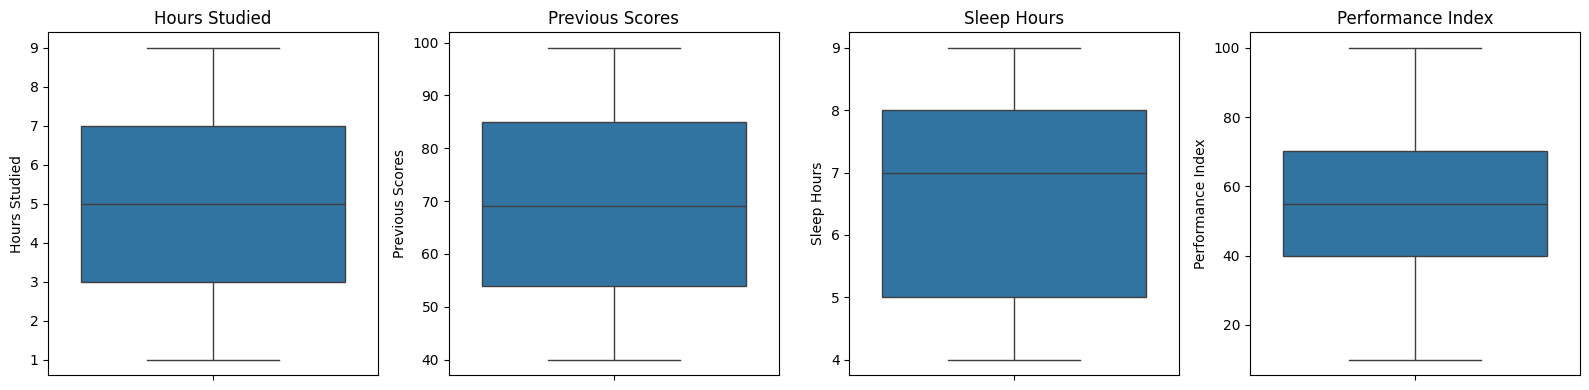

In [15]:
for col in ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Performance Index']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / len(df) * 100:.1f}%)  [valid range {low:.0f} to {high:.0f}]  min = {df[col].min():.0f}, max = {df[col].max():.0f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Performance Index']):
    sns.boxplot(y=df[col], ax=ax); ax.set_title(col)
plt.tight_layout()
plt.show()

**Decision:** all the values are inside realistic limits (hours 1–9, scores 40–99, sleep 4–9, index 10–100), so **nothing is removed** and no transformation of the target is needed. The IQR check above shows how many (if any) values fall outside the usual range.

## 3. EDA (visualization)

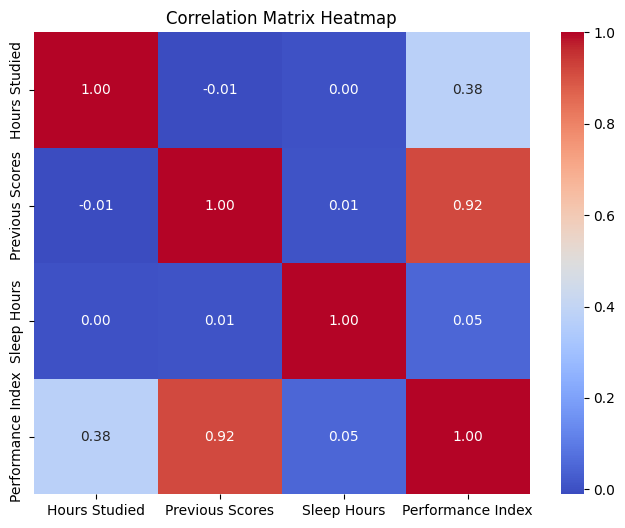

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

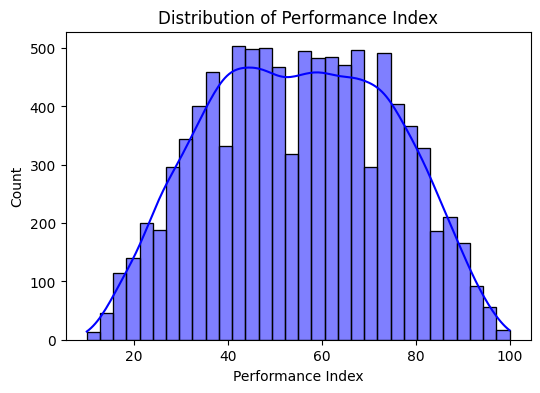

In [17]:
plt.figure(figsize=(6, 4))
sns.histplot(df['Performance Index'], kde=True, color='blue')
plt.title("Distribution of Performance Index")
plt.show()

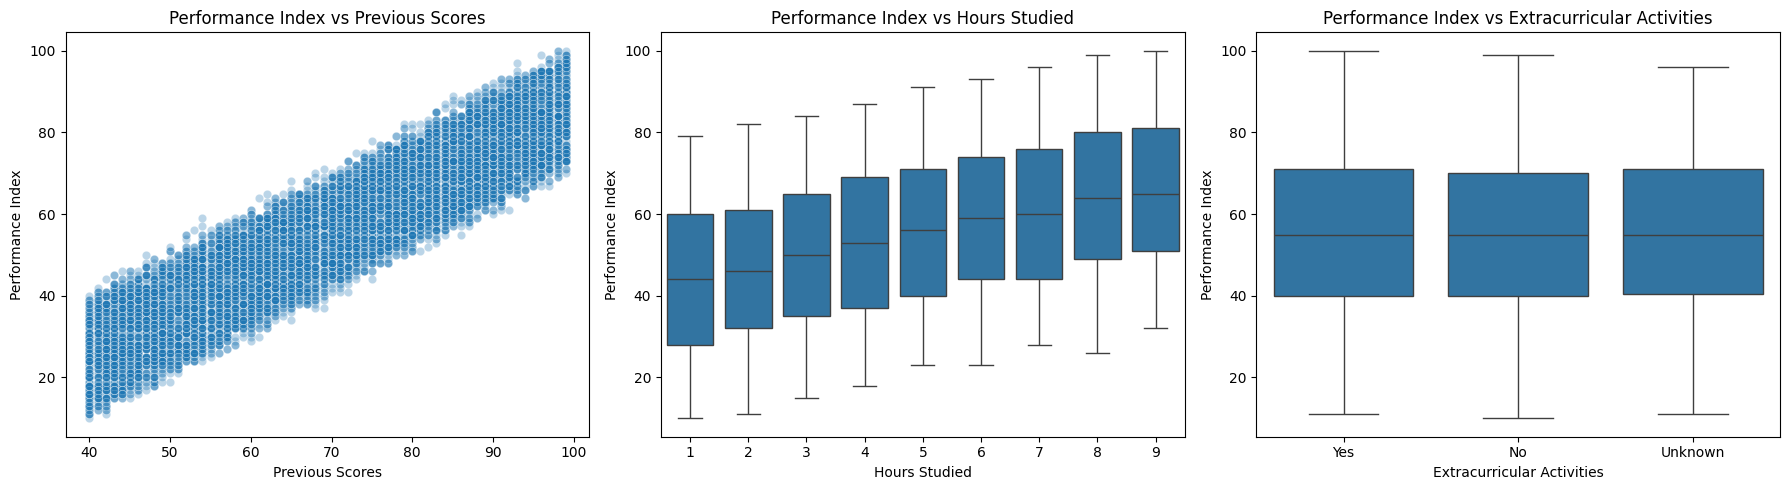

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(x='Previous Scores', y='Performance Index', data=df, alpha=0.3, ax=axes[0])
axes[0].set_title('Performance Index vs Previous Scores')
sns.boxplot(x='Hours Studied', y='Performance Index', data=df, ax=axes[1])
axes[1].set_title('Performance Index vs Hours Studied')
sns.boxplot(x='Extracurricular Activities', y='Performance Index', data=df, ax=axes[2])
axes[2].set_title('Performance Index vs Extracurricular Activities')
plt.tight_layout()
plt.show()

**What we see:** `Previous Scores` has a very strong, almost straight-line relation with the target (correlation ≈ 0.92), `Hours Studied` has a clear positive effect (≈ 0.37), `Sleep Hours` is almost unrelated (≈ 0.05). So we expect simple linear models to work very well.

## 4. Encoding

In [19]:
from sklearn.preprocessing import OneHotEncoder
onehotencoder = OneHotEncoder()
W = onehotencoder.fit_transform(df[['Extracurricular Activities']]).toarray()

for ind, col in enumerate(onehotencoder.categories_[0]):
    df[col] = W[:, ind]
    print(ind, col)

df.drop('Extracurricular Activities', axis=1, inplace=True)
df.columns = df.columns.astype(str)

0 No
1 Unknown
2 Yes


## 5. Train / Test split

In [20]:
y = df['Performance Index']
X = df.drop(columns=['Performance Index'])

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nTraining set shape (X_train):", X_train.shape)
print("Testing set shape (X_test):", X_test.shape)


Training set shape (X_train): (7894, 6)
Testing set shape (X_test): (1974, 6)


In [22]:
import re

for d in (X_train, X_test):
    d.columns = [re.sub(r'[^0-9a-zA-Z_]', '_', c) for c in d.columns]

print(X_train.columns)

Index(['Hours_Studied', 'Previous_Scores', 'Sleep_Hours', 'No', 'Unknown',
       'Yes'],
      dtype='object')


## 6. Scaling (fit on train only)

In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 7. Baseline: Linear Regression

In [24]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('\nMAE: ', mean_absolute_error(y_test, y_pred))
print('MSE: ', mean_squared_error(y_test, y_pred))
print('RMSE: ', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2: ', r2_score(y_test, y_pred))


MAE:  1.698768801168255
MSE:  4.510345343046842
RMSE:  2.1237573644479357
R2:  0.9880738532335844


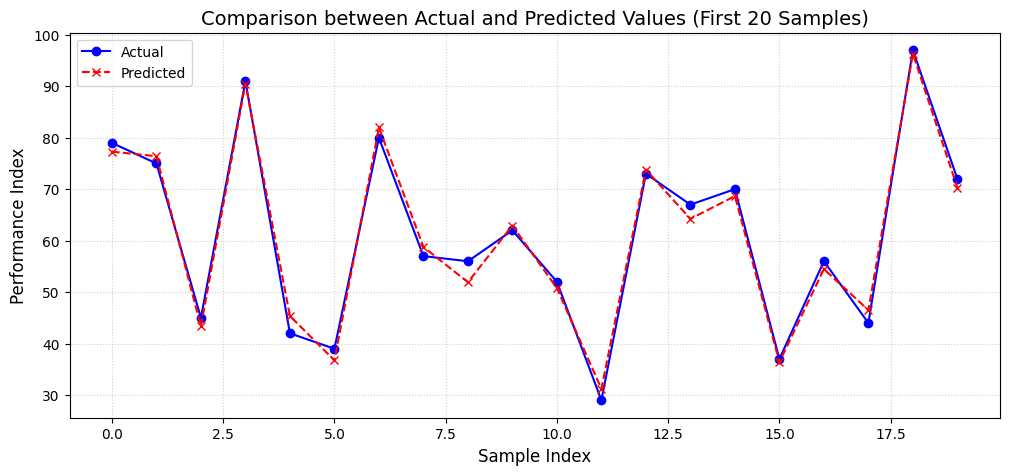

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:20], marker='o', linestyle='-', color='blue', label='Actual')
plt.plot(y_pred[:20], marker='x', linestyle='--', color='red', label='Predicted')

plt.xlabel('Sample Index', fontsize=12)
plt.ylabel('Performance Index', fontsize=12)
plt.title('Comparison between Actual and Predicted Values (First 20 Samples)', fontsize=14)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [27]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [28]:
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

## 8. All the models
KNN and LinearSVR use the scaled data (they depend on the scale of the features). The others use the original data.

In [29]:
import time
from joblib import Parallel, delayed

# 1) شيلي SVM (أبطأ موديل) أو استبدليه بـ LinearSVR
from sklearn.svm import LinearSVR

models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, p=1, n_jobs=-1),
    "LinearSVR": LinearSVR(C=100, max_iter=2000, random_state=42),   # بدل SVR
    "Decision Tree": DecisionTreeRegressor(max_depth=10),
    "Random Forest": RandomForestRegressor(n_estimators=50, max_depth=10, n_jobs=-1, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=10),
                                n_estimators=50, n_jobs=-1, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0, n_jobs=-1),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42, thread_count=-1),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1),
}

def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    mse = mean_squared_error(y_actual, y_pred)
    return mean_absolute_error(y_actual, y_pred), mse, np.sqrt(mse), r2_score(y_actual, y_pred)

needs_scaling = {"KNN", "LinearSVR"}      # these two are sensitive to the scale of the features

def fit_and_eval(name, model):
    Xtr, Xte = (X_train_scaled, X_test_scaled) if name in needs_scaling else (X_train, X_test)
    model.fit(Xtr, y_train)
    tr = regression_metrics(model, Xtr, y_train)
    te = regression_metrics(model, Xte, y_test)
    return name, model, {
        "MAE Train": tr[0], "MAE Test": te[0],
        "MSE Train": tr[1], "MSE Test": te[1],
        "RMSE Train": tr[2], "RMSE Test": te[2],
        "R2 Train": tr[3], "R2 Test": te[3],
    }

# 2) تدريب كل الموديلات بالتوازي
start = time.time()
results = Parallel(n_jobs=-1)(delayed(fit_and_eval)(n, clone(m)) for n, m in models.items())
errors = {name: metrics for name, _, metrics in results}
fitted = {name: m for name, m, _ in results}
print(f"Done in {time.time()-start:.1f}s")

Done in 15.7s


In [30]:
# Voting: model1 و model2 نفس الحاجة بالظبط، فاعملي واحد بس
rf  = RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=1)
voting = VotingRegressor([('lr', LinearRegression()), ('rf', rf), ('dt', DecisionTreeRegressor(random_state=1))], n_jobs=-1)
w_voting = VotingRegressor([('lr', LinearRegression()), ('rf', rf), ('dt', DecisionTreeRegressor(random_state=1))],
                           weights=[2, 1, 2], n_jobs=-1)

for name, m in [("Voting", voting), ("Weighted Voting", w_voting)]:
    _, fitted[name], errors[name] = fit_and_eval(name, m)

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


In [31]:
stacking = StackingRegressor(
    estimators=[
        ('rf',  RandomForestRegressor(n_estimators=30, n_jobs=-1, random_state=42)),
        ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1)),
        ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0, random_state=42)),
    ],
    final_estimator=Ridge(),   # بدل XGBoost: أسرع وكفاية للـ meta
    cv=3,
    n_jobs=-1
)
_, fitted["Stacking"], errors["Stacking"] = fit_and_eval("Stacking", stacking)

In [32]:
from sklearn.linear_model import ElasticNet
models["ElasticNet"] = ElasticNet()
_, fitted["ElasticNet"], errors["ElasticNet"] = fit_and_eval("ElasticNet", ElasticNet())

Best model on the test set (only for this picture): Ridge


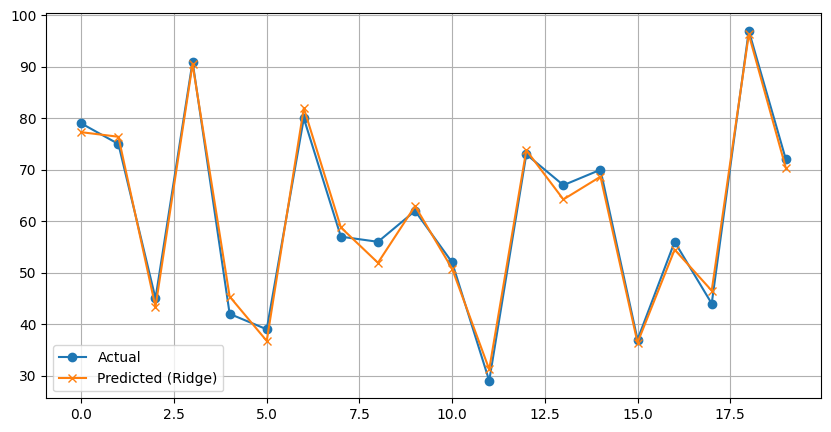

In [33]:
best = max(errors, key=lambda k: errors[k]["R2 Test"])
print("Best model on the test set (only for this picture):", best)
Xte_best = X_test_scaled if best in needs_scaling else X_test
plt.figure(figsize=(10,5))
plt.plot(y_test.values[:20], marker='o', label='Actual')
plt.plot(fitted[best].predict(Xte_best[:20]), marker='x', label=f'Predicted ({best})')
plt.legend(); plt.grid(); plt.show()

In [34]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [35]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Ridge,1.683532,1.698769,4.497380,4.510339,2.120703,2.123756,0.987748,0.988074
Linear Regression,1.683531,1.698769,4.497380,4.510345,2.120703,2.123757,0.987748,0.988074
LinearSVR,1.688997,1.699042,4.528436,4.513033,2.128012,2.124390,0.987664,0.988067
GradientBoosting,1.677158,1.764944,4.457231,4.822537,2.111216,2.196028,0.987858,0.987248
Stacking,1.635080,1.766183,4.221082,4.838211,2.054527,2.199593,0.988501,0.987207
CatBoost,1.683738,1.766715,4.474255,4.866687,2.115243,2.206057,0.987811,0.987132
HistGradientBoosting,1.593645,1.776980,4.014373,4.873612,2.003590,2.207626,0.989064,0.987113
LightGBM,1.593645,1.777120,4.014373,4.873818,2.003590,2.207673,0.989064,0.987113
XGBoost,1.540638,1.796852,3.771627,5.002670,1.942068,2.236665,0.989725,0.986772
Lasso,1.785776,1.807858,5.067426,5.059522,2.251094,2.249338,0.986195,0.986622


<Axes: >

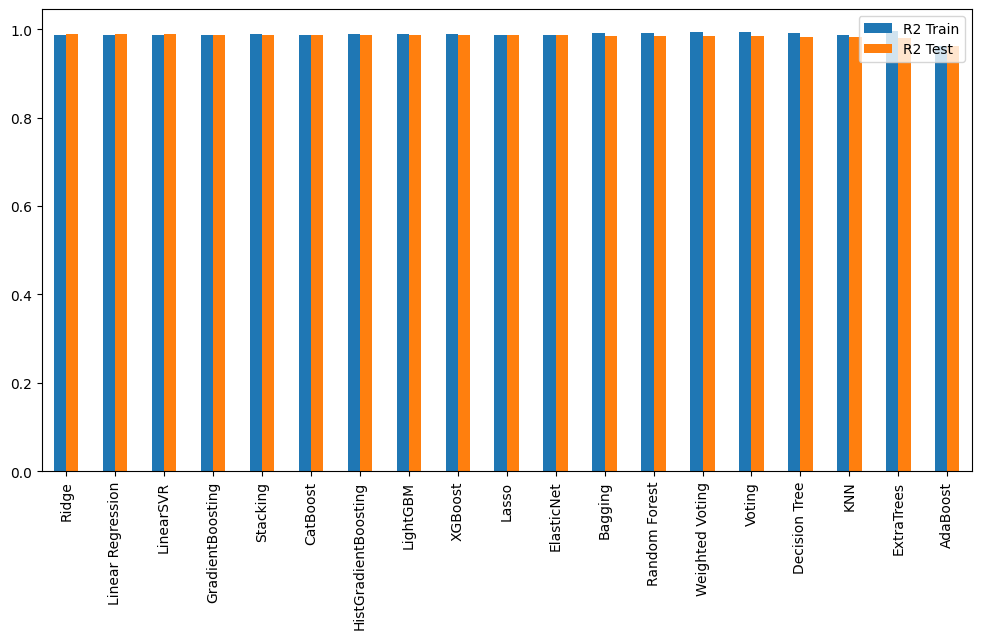

In [36]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

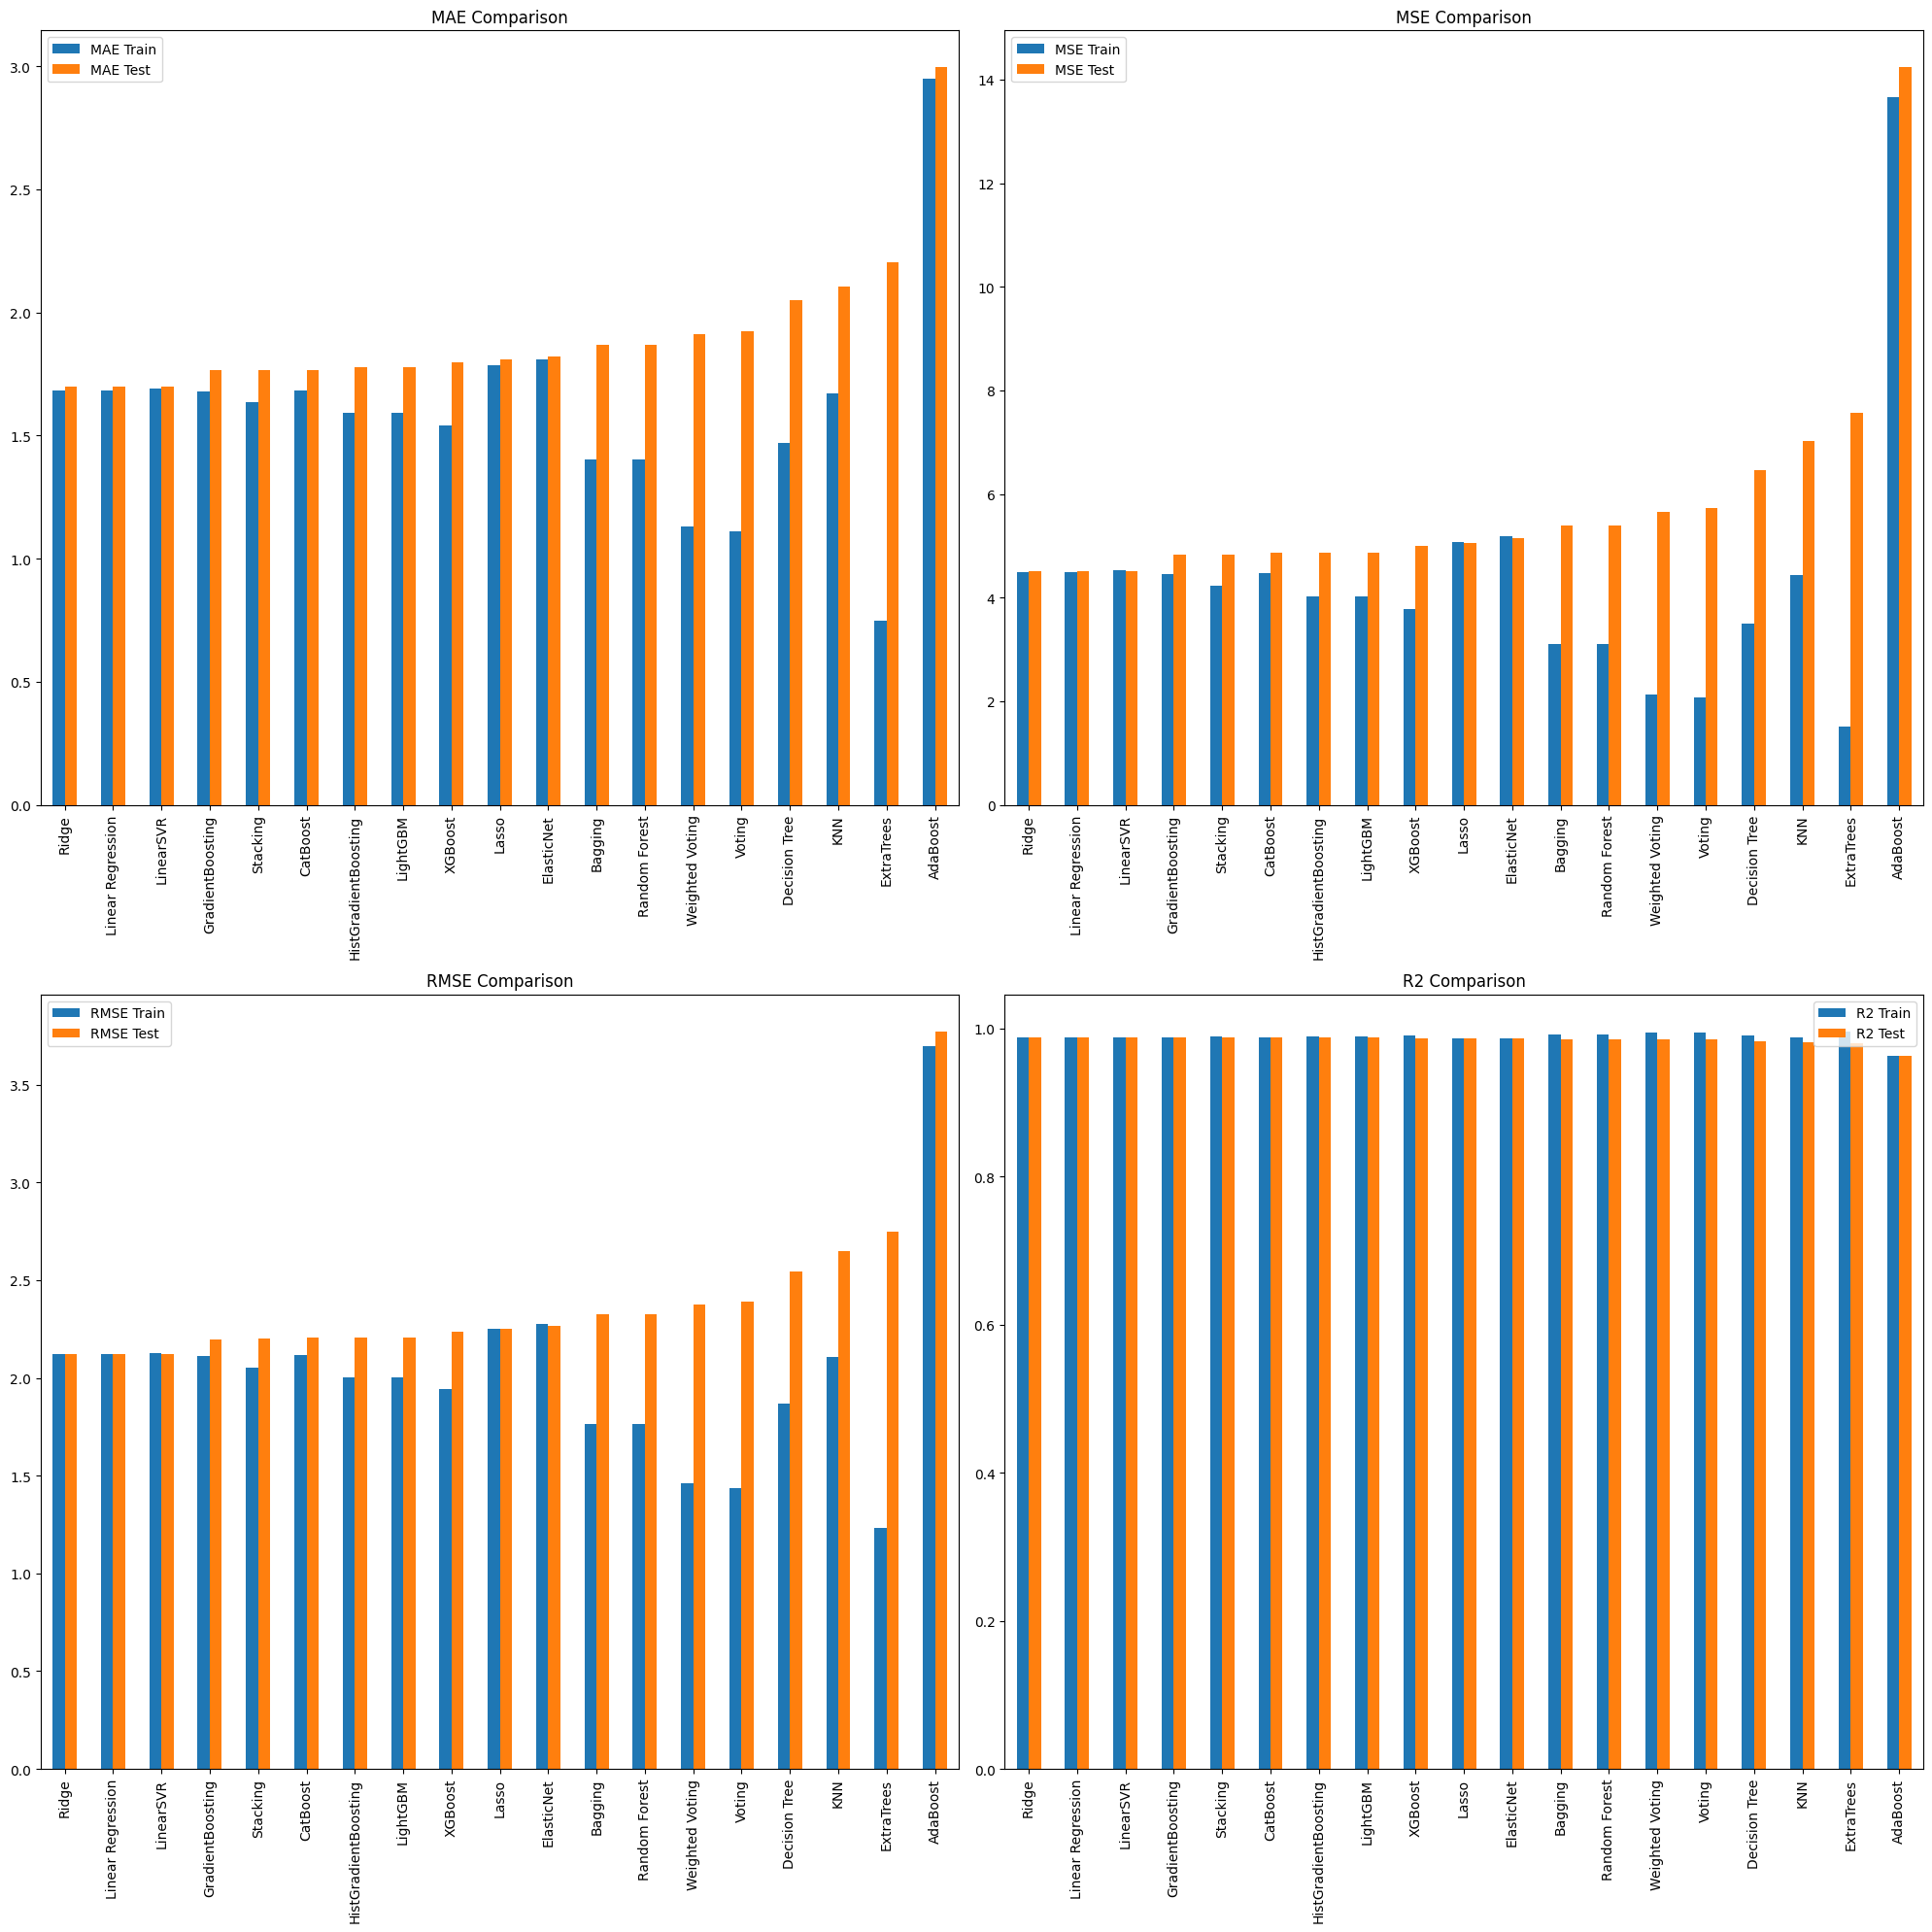

In [37]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** the table above uses the test set to show how each model behaves. To **choose** and **tune** the model we do not use the test set: we use cross-validation on the training data (next sections).

## 9. Model comparison with Cross-Validation (train data only)
5-fold cross-validation on the training data, metric **R²** (and RMSE). KNN and LinearSVR get a `StandardScaler` inside the pipeline, so the scaling is learned on each training fold only.

In [38]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def make_pipe(name, estimator):
    # scaler only for the models that need it
    scaler = StandardScaler() if name in needs_scaling else 'passthrough'
    return Pipeline([('scaler', scaler), ('model', clone(estimator))])

# all single models + the ensembles that were trained above
cv_models = dict(models)
cv_models.update({"Voting": voting, "Weighted Voting": w_voting, "Stacking": stacking})

cv_rows = {}
for name, est in tqdm(cv_models.items()):
    cv = cross_validate(make_pipe(name, est), X_train, y_train, cv=kf, n_jobs=-1,
                        scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'})
    cv_rows[name] = {'CV R2': cv['test_r2'].mean(), 'CV RMSE': -cv['test_rmse'].mean()}

cv_df = pd.DataFrame(cv_rows).T.sort_values('CV R2', ascending=False)
cv_df

 63%|██████▎   | 12/19 [00:14<00:09,  1.30s/it]/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
100%|██████████| 19/19 [00:47<00:00,  2.51s/it]


,CV R2,CV RMSE
Ridge,0.987713,2.122886
Linear Regression,0.987713,2.122886
LinearSVR,0.987520,2.139463
CatBoost,0.987248,2.162782
Stacking,0.987215,2.165528
GradientBoosting,0.986973,2.185976
HistGradientBoosting,0.986929,2.189539
LightGBM,0.986927,2.189640
XGBoost,0.986595,2.217322
Lasso,0.986159,2.253363


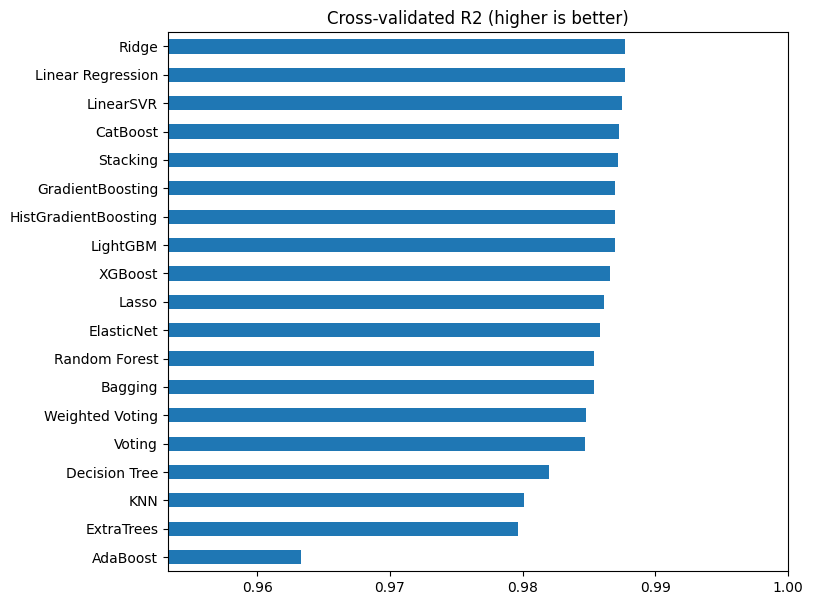

In [39]:
cv_df['CV R2'].sort_values().plot.barh(figsize=(8, 7))
plt.xlim(cv_df['CV R2'].min() - 0.01, 1)
plt.title('Cross-validated R2 (higher is better)')
plt.show()

**How to read it:** the relation between the features and the target is almost linear, so the linear models (Linear Regression, Ridge, ...) are at the top and the more complex models do not give a real gain. A model with a big gap between its Train R² (table above) and its CV R² is overfitting (e.g. Decision Tree, ExtraTrees). Weak models (AdaBoost, KNN, LinearSVR with its default settings) are not good candidates.

## 10. GridSearchCV on the best 3 models
The 3 best **single** models of the cross-validation comparison (Voting / Stacking are combinations of models and are not tuned here) are tuned with `GridSearchCV` (5-fold CV on the training data, metric R²). The test set is not used here.

In [40]:
param_grids = {
    'Linear Regression': {'model__fit_intercept': [True, False]},
    'Lasso': {'model__alpha': [0.0001, 0.001, 0.01, 0.1]},
    'Ridge': {'model__alpha': [0.01, 0.1, 1, 10, 100]},
    'ElasticNet': {'model__alpha': [0.0001, 0.001, 0.01], 'model__l1_ratio': [0.2, 0.5, 0.8]},
    'KNN': {'model__n_neighbors': [3, 5, 9, 15], 'model__weights': ['uniform', 'distance'], 'model__p': [1, 2]},
    'LinearSVR': {'model__C': [0.1, 1, 10], 'model__epsilon': [0.0, 0.1, 1.0], 'model__max_iter': [20000]},
    'Decision Tree': {'model__max_depth': [3, 5, 8, 12], 'model__min_samples_leaf': [1, 5, 10]},
    'Random Forest': {'model__n_estimators': [100, 300], 'model__max_depth': [8, 12, None], 'model__min_samples_leaf': [1, 3]},
    'ExtraTrees': {'model__n_estimators': [100, 300], 'model__max_depth': [8, 12, None], 'model__min_samples_leaf': [1, 3]},
    'Bagging': {'model__n_estimators': [50, 100], 'model__max_samples': [0.7, 1.0]},
    'AdaBoost': {'model__n_estimators': [50, 100, 200], 'model__learning_rate': [0.05, 0.1, 0.5, 1.0]},
    'GradientBoosting': {'model__n_estimators': [100, 300], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3, 5]},
    'HistGradientBoosting': {'model__max_iter': [100, 300], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [None, 6]},
    'XGBoost': {'model__n_estimators': [200, 400], 'model__max_depth': [2, 3, 5], 'model__learning_rate': [0.03, 0.1]},
    'CatBoost': {'model__iterations': [200, 500], 'model__depth': [4, 6], 'model__learning_rate': [0.05, 0.1]},
    'LightGBM': {'model__n_estimators': [200, 400], 'model__num_leaves': [7, 15, 31], 'model__learning_rate': [0.03, 0.1]},
}

top3 = [n for n in cv_df.index if n in param_grids][:3]
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    grid = GridSearchCV(make_pipe(name, models[name]), param_grids[name], cv=kf, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 4))
    summary.append([name, cv_df.loc[name, 'CV R2'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning (CV R2)', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['Ridge', 'Linear Regression', 'LinearSVR']

Ridge
  best_params_: {'model__alpha': 10}
  best_score_ : 0.9877

Linear Regression
  best_params_: {'model__fit_intercept': True}
  best_score_ : 0.9877

LinearSVR
  best_params_: {'model__C': 1, 'model__epsilon': 0.1, 'model__max_iter': 20000}
  best_score_ : 0.9877


,Before tuning (CV R2),After tuning (best_score_)
Model,,
Ridge,0.987713,0.987713
Linear Regression,0.987713,0.987713
LinearSVR,0.987520,0.987714


**Why these parameters:** `alpha` controls how strongly the coefficients are shrunk, depth / leaf size control the complexity of tree models (overfitting vs underfitting), `learning_rate` and the number of trees trade off in boosting, `n_neighbors` / `weights` control the smoothness of KNN. The grids are small on purpose: they keep the search fast and avoid tuning noise. When the models are almost equal (as here), the gain from tuning is tiny, so if several models are tied we choose the simplest one.

## 11. Final model and evaluation on the test set (used once)

In [41]:
# Choose the final model. If several models are practically tied (difference < 0.0005 in CV R2),
# we take the simplest one (linear models first): same quality, easier to explain, less risk of overfitting.
scores = tuning_df['After tuning (best_score_)']
tied = scores[scores >= scores.max() - 0.0005].index.tolist()
simple_first = [n for n in ['Linear Regression', 'Ridge', 'Lasso', 'ElasticNet'] if n in tied]
best_name = simple_first[0] if simple_first else scores.idxmax()
print("Models within 0.0005 of the best score:", tied)
best_model = tuned[best_name].best_estimator_
print("Best model:", best_name, tuned[best_name].best_params_)

y_pred_final = best_model.predict(X_test)

results = pd.Series({
    'MAE': mean_absolute_error(y_test, y_pred_final),
    'MSE': mean_squared_error(y_test, y_pred_final),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_final)),
    'R2': r2_score(y_test, y_pred_final),
}, name='Test set')
results

Models within 0.0005 of the best score: ['Ridge', 'Linear Regression', 'LinearSVR']
Best model: Linear Regression {'model__fit_intercept': True}


,Test set
MAE,1.698769
MSE,4.510345
RMSE,2.123757
R2,0.988074


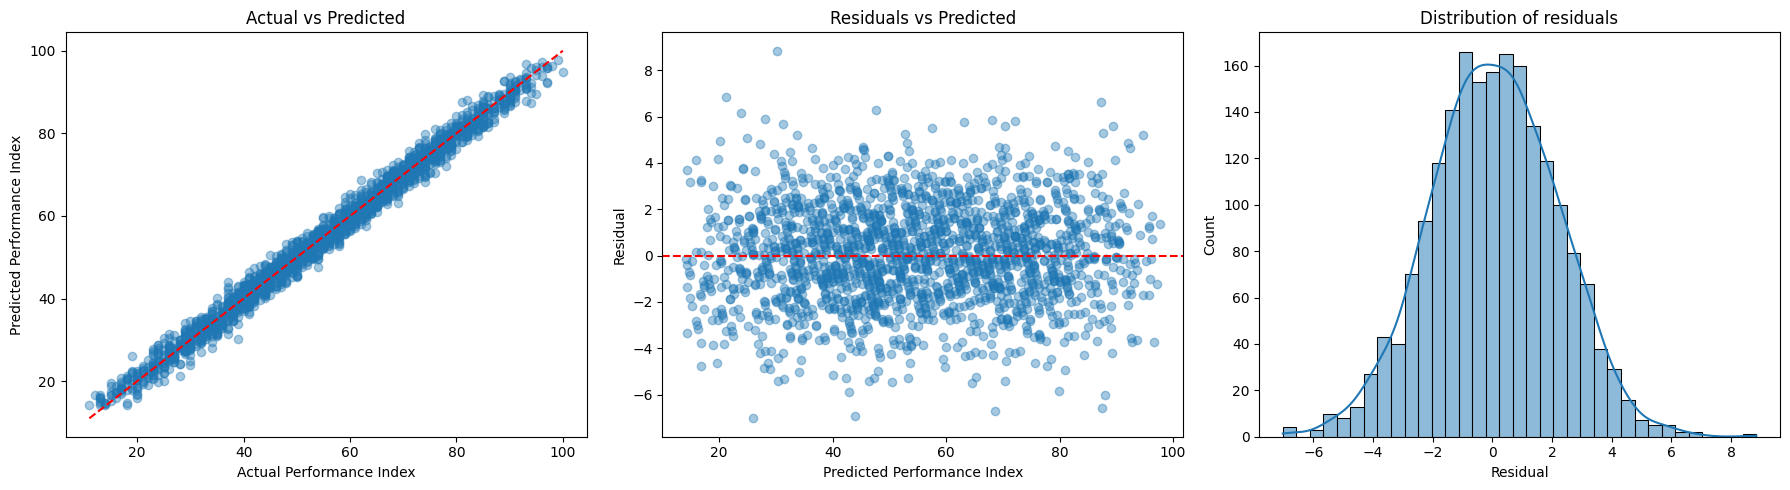

In [42]:
residuals = y_test - y_pred_final
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_test, y_pred_final, alpha=0.4)
lim = [y_test.min(), y_test.max()]
axes[0].plot(lim, lim, 'r--')
axes[0].set_title('Actual vs Predicted')
axes[0].set_xlabel('Actual Performance Index'); axes[0].set_ylabel('Predicted Performance Index')

axes[1].scatter(y_pred_final, residuals, alpha=0.4)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('Residuals vs Predicted')
axes[1].set_xlabel('Predicted Performance Index'); axes[1].set_ylabel('Residual')

sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set_title('Distribution of residuals')
axes[2].set_xlabel('Residual')
plt.tight_layout()
plt.show()

In [43]:
print("=== Automatic interpretation of the results ===")
print(f"- Selected model: {best_name}.")
print(f"- R2 = {results['R2']:.3f} -> the model explains {results['R2']:.1%} of the variation of the Performance Index.")
print(f"- MAE = {results['MAE']:.2f}: on average the prediction is {results['MAE']:.2f} points away from the real index "
      f"(RMSE = {results['RMSE']:.2f}; the index goes from {y_test.min():.0f} to {y_test.max():.0f}).")
print(f"- {(np.abs(residuals) <= 5).mean():.0%} of the students are predicted within +-5 points.")
print(f"- Mean residual = {residuals.mean():.3f} (close to 0 means no systematic over/under prediction).")
best_cv = cv_df['CV R2'].iloc[0]; worst_top = cv_df['CV R2'].iloc[min(4, len(cv_df) - 1)]
print(f"- The best 5 models differ by only {best_cv - worst_top:.4f} in CV R2: the data is almost linear, so a simple model is enough.")

=== Automatic interpretation of the results ===
- Selected model: Linear Regression.
- R2 = 0.988 -> the model explains 98.8% of the variation of the Performance Index.
- MAE = 1.70: on average the prediction is 1.70 points away from the real index (RMSE = 2.12; the index goes from 11 to 100).
- 98% of the students are predicted within +-5 points.
- Mean residual = 0.058 (close to 0 means no systematic over/under prediction).
- The best 5 models differ by only 0.0005 in CV R2: the data is almost linear, so a simple model is enough.


**Interpretation**
- **R²** close to 1 means the model explains almost all the variation of the Performance Index.
- **MAE** is the average error in index points; **RMSE** is a little bigger because it punishes the larger errors more. **MSE** is the same error squared.
- **Actual vs Predicted:** points on the red diagonal are perfect predictions; here they stay very close to it.
- **Residuals vs Predicted:** a random cloud around 0 is what we want. A curve or funnel would show that the model misses a pattern.
- **Histogram of residuals:** bell-shaped and centred on 0 means the errors are balanced (no systematic over- or under-prediction).
- **Why simple models win:** the Performance Index is almost a straight-line function of `Previous Scores` and `Hours Studied`, so complex models (boosting, stacking) cannot add much and some of them overfit.
- **Limits:** the dataset looks synthetic (very clean, no outliers). Real student data is noisier, so real-life results would be lower.

## 12. Conclusions
- Missing values were handled without data leakage (`Unknown` category; the column with 28% missing values and almost no relation to the target was dropped).
- `Previous Scores` and `Hours Studied` are the main drivers of the Performance Index; sleep hours and extracurricular activities have a small effect.
- The final model was chosen with cross-validation, tuned with `GridSearchCV`, and evaluated on the test set only once.
- Possible improvements: collect more features (attendance, family situation, ...), test the model on real (noisier) data.